# Evidencia de Aprendizaje 2 — Optimizando la productividad en el mundo del software

**Estudiante:** Jeremy Iván Pedraza Hernández
**Programa:** Ingeniería de Software y Datos — Institución Universitaria Digital de Antioquia
**Sitio analizado:** Mercado Libre Colombia (`mercadolibre.com.co`)
**Artículo analizado:** Samsung Galaxy A55 5G 256 GB — categoría *Celulares y Smartphones*

**Objetivo del notebook:** evidenciar cómo el scraping de la EA1 se convirtió en un proyecto de
software gestionado con **Git y GitHub** (ramas, *commits* descriptivos, fusiones y *pull requests*)
y con un flujo **DevOps** de **integración continua** (pruebas automatizadas con `pytest`) y
**despliegue continuo** (reporte publicado en GitHub Pages) implementado con **GitHub Actions**.

| Fase | Contenido |
|---|---|
| 0 | Configuración: ubicación del repositorio y del paquete `ml_scraper` |
| 1 | Control de versiones: ramas, historial y convención de *commits* |
| 2 | Pruebas automatizadas y cobertura (lo mismo que ejecuta CI) |
| 3 | Ejecución del pipeline de scraping (lo mismo que ejecuta CD) |
| 4 | Workflows de GitHub Actions: CI y CD |
| 5 | Resultados y conclusiones |

## Fase 0. Configuración del entorno

> **Google Colab:** si el cuaderno no se ejecuta dentro del repositorio, la celda clona el
> repositorio público e instala el paquete. En local se usa la carpeta padre de `notebooks/`.

In [1]:
import subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/USUARIO/scraping-ml-devops.git"

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
if RAIZ is None:  # Colab u otra ubicación
    subprocess.run(["git", "clone", "-q", REPO_URL, "scraping-ml-devops"], check=True)
    RAIZ = Path("scraping-ml-devops").resolve()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(RAIZ), "pytest", "pytest-cov"], check=True)

sys.path.insert(0, str(RAIZ / "src"))
import ml_scraper
print("Repositorio:", RAIZ.name, "| ml_scraper", ml_scraper.__version__, "| Python", sys.version.split()[0])


def sh(*cmd: str) -> str:
    """Ejecuta un comando en la raíz del repositorio y devuelve su salida."""
    r = subprocess.run(cmd, cwd=RAIZ, capture_output=True, text=True, encoding="utf-8")
    return (r.stdout + r.stderr).strip()

Repositorio: scraping-ml-devops | ml_scraper 1.0.0 | Python 3.10.6


## Fase 1. Control de versiones con Git y GitHub

El repositorio sigue un **GitFlow simplificado**: `main` contiene lo que está en producción (cada
*commit* se despliega), `develop` integra funcionalidades terminadas y cada funcionalidad se
desarrolla en una rama `feature/*`. Las ramas se fusionan con `--no-ff` (en GitHub, *Create a merge
commit* de un *pull request*) para que el historial muestre explícitamente cada integración.

In [2]:
print(sh("git", "log", "--graph", "--oneline", "--all", "--decorate"))

* 304294b (HEAD -> docs/notebook-ea2) chore(coverage): excluir el punto de entrada __main__ de la medición
*   c433b86 (develop) Merge branch 'feature/cd-github-pages' into develop
|\  
| * 0224670 (feature/cd-github-pages) docs(readme): propósito, estructura, ejecución y flujo DevOps
| * e87507f ci(cd): despliegue continuo del reporte en GitHub Pages
|/  
*   24db1ac Merge branch 'feature/ci-github-actions' into develop
|\  
| * 2739027 (feature/ci-github-actions) docs: guía de contribución, modelo de ramas y plantilla de PR
| * 3e19b33 ci: workflow de integración continua con ruff, pytest y Scrapy
|/  
*   4c8adec Merge branch 'feature/analisis-reporte' into develop
|\  
| * a97c653 (feature/analisis-reporte) feat(pipeline): orquestador de las cinco fases y CLI python -m ml_scraper
| * 58af56c feat(reporte): gráfico y sitio estático con los resultados
| * 5660698 feat(analisis): indicadores de posicionamiento y métricas de éxito
|/  
*   4ea08f6 Merge branch 'feature/rastreo-competen

In [3]:
print("RAMAS")
print(sh("git", "branch", "-a"))

RAMAS
develop
* docs/notebook-ea2
  feature/analisis-reporte
  feature/cd-github-pages
  feature/ci-github-actions
  feature/extraccion-producto
  feature/rastreo-competencia
  main


### 1.1 Convención de mensajes (*Conventional Commits*)

Cada mensaje sigue el patrón `tipo(alcance): descripción`. La tabla clasifica el historial por tipo
para verificar la convención.

In [4]:
import re
import pandas as pd

mensajes = sh("git", "log", "--all", "--no-merges", "--pretty=%s").splitlines()
tipos = [m.group(1) if (m := re.match(r"(\w+)(\(.+?\))?:", s)) else "otro" for s in mensajes]
fusiones = len(sh("git", "log", "--all", "--merges", "--pretty=%h").splitlines())

df_commits = pd.Series(tipos).value_counts().rename_axis("Tipo").reset_index(name="Commits")
print(f"Commits sin fusión: {len(mensajes)} | Fusiones (--no-ff): {fusiones} | "
      f"Cumplen la convención: {sum(t != 'otro' for t in tipos)}/{len(tipos)}")
df_commits

Commits sin fusión: 14 | Fusiones (--no-ff): 5 | Cumplen la convención: 14/14


,Tipo,Commits
0,feat,8
1,chore,2
2,docs,2
3,ci,2


## Fase 2. Pruebas automatizadas

La EA1 era un cuaderno: verificar que seguía funcionando exigía ejecutarlo y revisar las salidas a
mano. En la EA2 la lógica se trasladó al paquete `ml_scraper` y se cubrió con **30 pruebas**
`pytest` de tres tipos:

* **Unitarias:** normalización de precios, extracción defensiva, cálculo de descuentos.
* **Regresión:** la conclusión de negocio de la EA1 (+17,05 % sobre el promedio) debe mantenerse.
* **Integración:** el pipeline completo genera los CSV, el gráfico y el `index.html` que se despliega.

Esta es exactamente la orden que ejecuta el workflow **CI** en cada *push* y *pull request*.

In [5]:
salida = sh(sys.executable, "-m", "pytest", "--cov", "--cov-report=term", "-q", "--color=no", "-p", "no:cacheprovider")
print(salida[-2600:])

..............................                                           [100%]
=============================== tests coverage ================================
_______________ coverage: platform win32, python 3.10.6-final-0 _______________

Name                            Stmts   Miss  Cover   Missing
-------------------------------------------------------------
src\ml_scraper\__init__.py          1      0   100%
src\ml_scraper\analisis.py         21      0   100%
src\ml_scraper\competencia.py      21      2    90%   27-28
src\ml_scraper\pipeline.py         46      1    98%   48
src\ml_scraper\producto.py         23      0   100%
src\ml_scraper\reporte.py          68      0   100%
src\ml_scraper\resenas.py          32     13    59%   26-41, 46
src\ml_scraper\utils.py            27      0   100%
-------------------------------------------------------------
TOTAL                             239     16    93%
30 passed in 6.66s


## Fase 3. Ejecución del pipeline de scraping

`pipeline.ejecutar()` encadena las cinco fases de la EA1 —BeautifulSoup, Selenium, Scrapy, pandas y
reporte— y produce el sitio estático que el workflow **CD** publica en GitHub Pages. Se ejecuta en
modo *offline* sobre el *snapshot* versionado en `data/`, igual que en CI/CD.

In [6]:
from ml_scraper import pipeline

r = pipeline.ejecutar(offline=True, out_dir=RAIZ / "out", site_dir=RAIZ / "site")
print("Motor de reseñas:", r["motor_resenas"])
print("Sitio generado :", r["index"].relative_to(RAIZ))
pd.DataFrame(r["ficha"].items(), columns=["Campo", "Valor"])

Motor de reseñas: snapshot
Sitio generado : site\index.html


,Campo,Valor
0,titulo,Samsung Galaxy A55 5G 256 GB Azul Oscuro 8 GB RAM
1,condicion_ventas,Nuevo | +500 vendidos
2,precio_actual,1499900
3,precio_anterior,1899900
4,descuento,21% OFF
5,calificacion,4.7
6,n_opiniones,1284
7,vendedor,SAMSUNG COLOMBIA
8,reputacion_vendedor,MercadoLider Platinum
9,stock,Stock disponible (12 unidades)


In [7]:
pd.DataFrame(r["especificaciones"].items(), columns=["Atributo", "Valor"])

,Atributo,Valor
0,Marca,Samsung
1,Linea,Galaxy A
2,Modelo,SM-A556E
3,Memoria interna,256 GB
4,Memoria RAM,8 GB
5,Tamano de la pantalla,"6.6 """
6,Camara trasera principal,50 Mpx
7,Bateria,5000 mAh
8,Con 5G,Si


In [8]:
pd.DataFrame(r["resenas"])

,comentario,estrellas
0,"Excelente relacion precio calidad, la bateria ...",5
1,"La camara responde bien de dia, de noche es re...",4
2,"Llego antes de lo previsto y sellado, muy buen...",5
3,"Se calienta un poco al jugar, por lo demas cum...",3
4,"Buen equipo para el precio, la pantalla se ve ...",5


In [9]:
r["competencia"][["posicion", "titulo", "precio", "descuento_pct", "calificacion",
                  "n_opiniones", "envio_gratis", "es_articulo_analizado"]]

,posicion,titulo,precio,descuento_pct,calificacion,n_opiniones,envio_gratis,es_articulo_analizado
0,1,Samsung Galaxy A55 5G 256 GB Azul Oscuro 8 GB RAM,1499900,21,4.7,1284,True,True
1,2,Samsung Galaxy A55 5G 128 GB Azul Claro 8 GB RAM,1349900,21,4.6,842,True,False
2,3,Samsung Galaxy A35 5G 256 GB Azul Helado 8 GB RAM,1199900,20,4.6,615,True,False
3,4,Samsung Galaxy A56 5G 256 GB Gris 8 GB RAM,1799900,14,4.8,203,True,False
4,5,Xiaomi Redmi Note 14 Pro 5G 256 GB Negro 8 GB RAM,1289900,19,4.7,1930,True,False
5,6,Xiaomi Poco X7 Pro 5G 512 GB Amarillo 12 GB RAM,1649900,18,4.8,756,True,False
6,7,Motorola Edge 50 Fusion 256 GB Azul 8 GB RAM,1199000,25,4.5,489,False,False
7,8,Motorola Moto G85 5G 256 GB Verde 8 GB RAM,999900,23,4.4,1120,True,False
8,9,Honor 200 Lite 5G 256 GB Negro 8 GB RAM,1099900,21,4.5,318,False,False
9,10,Realme 13 Pro 5G 256 GB Morado 8 GB RAM,1259000,19,4.6,274,True,False


### 3.1 Indicadores de posicionamiento y métricas de éxito

In [10]:
pd.DataFrame(r["indicadores"].items(), columns=["Métrica", "Valor"])

,Métrica,Valor
0,Artículos rastreados,12.00
1,Precio del artículo analizado (COP),1499900.00
2,Precio mínimo del mercado (COP),899900.00
3,Precio máximo del mercado (COP),1799900.00
4,Precio promedio del mercado (COP),1281416.00
5,Mediana del mercado (COP),1229450.00
6,Desviación vs. promedio (%),17.05
7,Ranking de precio (1 = más barato),10.00
8,Descuento promedio del mercado (%),20.90
9,Ofertas con envío gratis (%),66.70


In [11]:
r["metricas"]

,Métrica,Criterio,Resultado,Cumple
0,Cobertura de campos de la ficha,≥ 10 campos,22,True
1,Especificaciones técnicas,≥ 5 atributos,9,True
2,Contenido dinámico,≥ 3 opiniones,5,True
3,Cobertura del mercado,≥ 10 competidores,12,True


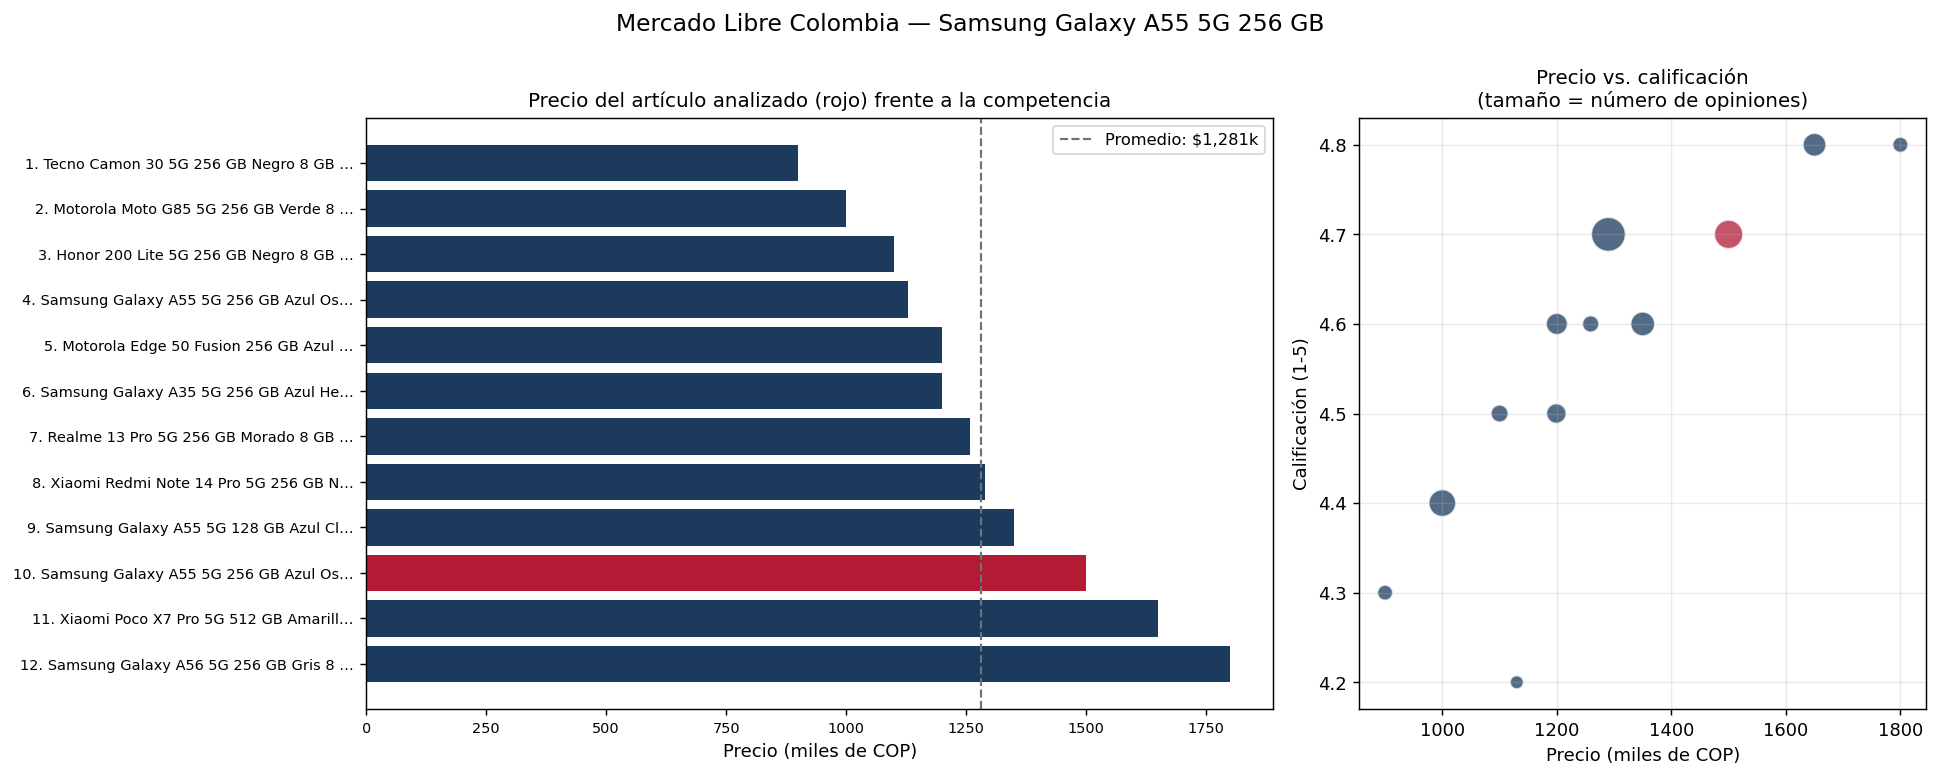

In [12]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "site" / "analisis_precios.png"), width=950))

## Fase 4. Flujo DevOps con GitHub Actions

| Workflow | Disparador | Trabajos |
|---|---|---|
| `ci.yml` | *push* a cualquier rama de trabajo y *pull request* hacia `main`/`develop` | `lint` (ruff) → `test` (matriz 3.10/3.11/3.12, cobertura ≥ 85 %) y `scrapy` |
| `cd.yml` | *push* a `main`, etiquetas `v*` o ejecución manual | `build` (pruebas + pipeline) → `deploy` (GitHub Pages) → `smoke` (curl al sitio) |

In [13]:
for nombre in ("ci.yml", "cd.yml"):
    texto = (RAIZ / ".github" / "workflows" / nombre).read_text(encoding="utf-8")
    trabajos = re.findall(r"^  (\w+):\n    name: (.+)$", texto, flags=re.M)
    print(f"{nombre}")
    for clave, titulo in trabajos:
        dep = re.search(rf"^  {clave}:\n(?:    .+\n)*?    needs: (.+)$", texto, flags=re.M)
        print(f"   - {clave:7} {titulo:42} needs: {dep.group(1) if dep else '—'}")

ci.yml
   - lint    Lint (ruff)                                needs: —
   - test    Pruebas (Python ${{ matrix.python-version }}) needs: lint
   - scrapy  Araña Scrapy (snapshot)                    needs: lint
cd.yml
   - build   Probar y construir el reporte              needs: —
   - deploy  Desplegar en GitHub Pages                  needs: build
   - smoke   Prueba de humo del despliegue              needs: deploy


In [14]:
print((RAIZ / ".github" / "workflows" / "cd.yml").read_text(encoding="utf-8"))

# Despliegue continuo: cada fusión en main vuelve a probar, ejecuta el pipeline de scraping
# y publica el reporte resultante en GitHub Pages.
# Requisito único: Settings → Pages → Source = "GitHub Actions".
name: CD

on:
  push:
    branches: [main]
    tags: ["v*"]
  workflow_dispatch:
    inputs:
      en_vivo:
        description: "Ejecutar el scraping contra el sitio real (en lugar del snapshot)"
        type: boolean
        default: false

permissions:
  contents: read
  pages: write
  id-token: write

concurrency:
  group: pages
  cancel-in-progress: false

jobs:
  build:
    name: Probar y construir el reporte
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.12"
          cache: pip
      - name: Instalar
        run: |
          pip install -r requirements-dev.txt
          pip install -e .
      - name: Pruebas (puerta de calidad antes de desplegar)
        run: pytest -q 

## Fase 5. Resultados y conclusiones

**Resultados**

1. El código de la EA1 se reorganizó en un paquete de seis módulos (`utils`, `producto`, `resenas`,
   `competencia`, `analisis`, `reporte`) más un orquestador, y la araña de Scrapy reutiliza la misma
   lógica de extracción que validan las pruebas.
2. El historial evidencia el flujo de ramas: cada funcionalidad nació en una rama `feature/*`,
   se integró en `develop` mediante fusión sin avance rápido y la versión se promueve a `main`
   mediante *pull request*.
3. Las 30 pruebas automatizadas pasan con una cobertura superior al 85 %, y la prueba de regresión
   confirma que la refactorización no alteró la conclusión de negocio de la EA1: el artículo se
   ofrece **17,05 % por encima del promedio** de su mercado y ocupa el puesto **10 de 12** por precio.
4. Cada fusión en `main` vuelve a probar el código, ejecuta el scraping y publica el reporte en
   GitHub Pages, con una prueba de humo que verifica que el sitio desplegado responde.

**Conclusiones**

* Git y GitHub convierten un cuaderno aislado en un activo trazable: cada cambio tiene autor,
  motivo y revisión, y cualquier versión puede reconstruirse.
* Las pruebas automatizadas son la condición que hace seguro el despliegue continuo: sin ellas,
  publicar en cada fusión solo automatizaría la propagación de errores.
* Separar la lógica de extracción del origen del HTML (snapshot o sitio real) fue la decisión que
  permitió probar el scraping en CI de forma determinista y sin generar tráfico hacia Mercado Libre.